# [Bonus Tasks](svm_segm.ipynb)

In [108]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.ndimage as ndi
import skimage.morphology as morph
import skimage.util
from skimage.util import view_as_blocks
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [109]:
def blend_result(img, seg, border_radius=1, interior_opacity=1, interior_opacity_decay=0.9, color=(0,1,0)):
    img  = np.dstack([img] * 3).copy()
    img -= img.min()
    img /= img.max()
    selem  = morph.disk(border_radius)
    seg_bd = np.logical_xor(morph.binary_dilation(seg, selem), morph.binary_erosion(seg, selem))
    mask_decay = ndi.distance_transform_edt(seg)
    for i in range(3):
        opacity = interior_opacity / pow(1 + mask_decay[seg], interior_opacity_decay)
        img[:,:,i][seg] = color[i] * opacity + (1 - opacity) * img[:,:,i][seg]
        img[:,:,i][seg_bd] = color[i]
    return img

In [110]:
patch_sizes = (32, 32)

---

**[Task 1.1.]()** Implement `create_data_matrix`:

In [133]:
def create_data_matrix(img):
    ph, pw = patch_sizes
    blocks = view_as_blocks(img, (ph, pw))
    X = blocks.reshape (-1, ph * pw)
    return X

print(type(img))

<class 'numpy.ndarray'>


**[Task 1.2.]()** Implement `create_gt_labels_vector`:

In [ ]:
def create_gt_labels_vector(gt):
    gt = gt.astype(bool)
    patch = create_data_matrix(gt)
    fg_fraction = patch.mean (axis = 1)

    labels = np.zeros(len(fg_fraction), dtype=int)
    labels[fg_fraction > 0.5] = 1
    labels [fg_fraction == 0] = -1
    return labels

**[Task 1.3.]()** Create the SVM classifier:

In [173]:
clf = make_pipeline(StandardScaler(), SVC(class_weight='balanced', gamma=0.1))

**[Task 1.3 (a).]()** Create the data matrices for the images `dna-33` and `dna-44`:

In [174]:
img33 = plt.imread('data/NIH3T3/im/dna-33.png')
img44 = plt.imread('data/NIH3T3/im/dna-44.png')

X33 = create_data_matrix(img33)
X44 = create_data_matrix(img44)

**[Task 1.3 (b).]()** Create the corresponding ground truth label vectors:

In [175]:
gt33 = plt.imread('data/NIH3T3/gt/33.png')
gt44 = plt.imread('data/NIH3T3/gt/44.png')

y33 = create_gt_labels_vector(gt33)
y44 = create_gt_labels_vector(gt44)

**[Task 1.3 (c).]()** Create the *combined* data matrices and ground truth label vectors:

In [176]:
X = np.concatenate([X33, X44])
Y = np.concatenate([y33, y44])

mask = Y != 0          
X = X[mask]
Y = Y[mask]


**[Task 1.3 (d).]()** Train the classifier using the data matrix and label vectors from above:

In [177]:
clf.fit(X, Y)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(class_weight='balanced', gamma=0.1))])

**[Task 1.4.]()** Implement the function `predict_image`:

In [178]:
def predict_image(img):
    ph, pw = patch_sizes
    X = create_data_matrix(img)                              
    labels = clf.predict(X)  

    grid = (labels ==1).reshape(img.shape [0] //ph,
                                img.shape [1] //pw)
    
    n_rows = grid.shape[0]
    n_cols = grid.shape[1]
   
    result = np.zeros(img.shape, dtype=bool)                 
    for row in range(n_rows):
          for col in range(n_cols):
      
             result[row * ph:(row+1)*ph, col*pw:(col+1)*pw] = grid[row,col]
    return result



Test your implementation:

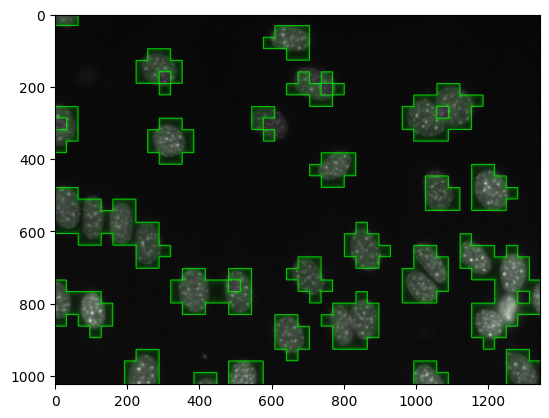

In [179]:
img = plt.imread(f'data/NIH3T3/im/dna-0.png')
seg = predict_image(img)

plt.figure()
plt.imshow(blend_result(img, seg))

Text(0.5, 1.0, 'Blend result')

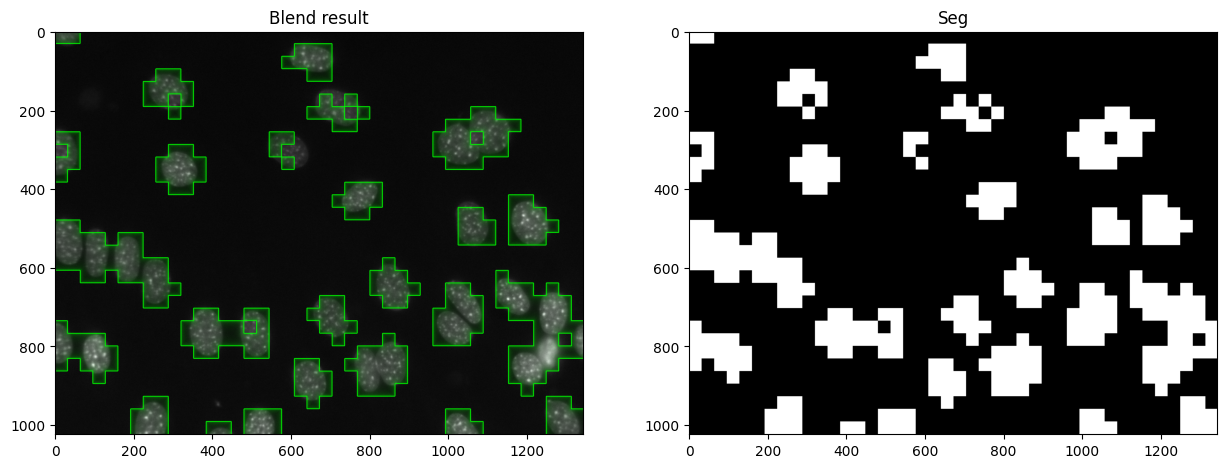

In [180]:

plt.figure(figsize=(15, 6))
plt.subplot(1, 2, 2); plt.imshow(seg, cmap='gray'); plt.title('Seg')
plt.subplot(1, 2, 1); plt.imshow(blend_result(img, seg));  plt.title('Blend result')

**[Task 1.5.]()** Perform batch processing:

In [181]:
def compute_dice(G, H):
    assert G.dtype == bool and H.dtype == bool
    dice = 2 * (G * H).sum() / (G.sum() + H.sum())
    return dice

indices = [28, 29, 33, 44, 46, 49]
dice_scores = []

for i in indices:
    img = plt.imread(f'data/NIH3T3/im/dna-{i}.png')
    gt = plt.imread(f'data/NIH3T3/gt/{i}.png')
    seg = predict_image(img)
    d = compute_dice(seg, gt.astype(bool))
    dice_scores.append(d)
    print(f'Image{i}:Dice = {d: .4f}')
print(f'Mean Dice:{np.mean(dice_scores):.4f}')

Image28:Dice =  0.7210
Image29:Dice =  0.6601
Image33:Dice =  0.6779
Image44:Dice =  0.7125
Image46:Dice =  0.6171
Image49:Dice =  0.6890
Mean Dice:0.6796
